# Project 05: Ensemble Learning Benchmark

## Problem Statement
How do different tree-based Machine Learning algorithms
compare when solving the same classification problem?

## Objective
Benchmark Decision Tree, Random Forest, and Gradient
Boosting using a consistent evaluation strategy.

## Models
1. Decision Tree
2. Random Forest
3. Gradient Boosting

## Techniques
- Stratified train/test splitting
- Stratified K-Fold Cross-Validation
- Accuracy and Macro F1-score
- Confusion matrices
- Feature importance analysis
- Generalization and overfitting analysis

## Dataset
Breast Cancer Wisconsin Diagnostic dataset from scikit-learn.

## Tools
Python, NumPy, Pandas, Matplotlib, Scikit-learn

## Important Note
This is an educational ML experiment, not a medical
diagnostic system.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Ensemble Learning Benchmark is ready!")

Ensemble Learning Benchmark is ready!


In [2]:
# Load the Breast Cancer Wisconsin Diagnostic dataset
cancer = load_breast_cancer(as_frame=True)

# Features and target
X = cancer.data.copy()
y = cancer.target.copy()

# Create a DataFrame for exploration
df = X.copy()
df["Target"] = y
df["Diagnosis"] = y.map(
    dict(enumerate(cancer.target_names))
)

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", list(cancer.target_names))

print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!
Number of samples: 569
Number of features: 30
Target classes: [np.str_('malignant'), np.str_('benign')]

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


In [3]:
print("Class distribution:")
display(df["Diagnosis"].value_counts())

print("\nClass proportions (%):")
display(
    (df["Diagnosis"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nFeatures with the largest numerical ranges:")
feature_ranges = pd.DataFrame({
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Range": X.max() - X.min()
})

display(
    feature_ranges.sort_values(
        "Range", ascending=False
    ).head(10)
)

Class distribution:


Diagnosis
benign       357
malignant    212
Name: count, dtype: int64


Class proportions (%):


Diagnosis
benign       62.74
malignant    37.26
Name: proportion, dtype: float64


Missing values:
0

Features with the largest numerical ranges:


,Minimum,Maximum,Range
worst area,185.200,4254.00,4068.800
mean area,143.500,2501.00,2357.500
area error,6.802,542.20,535.398
worst perimeter,50.410,251.20,200.790
mean perimeter,43.790,188.50,144.710
worst texture,12.020,49.54,37.520
mean texture,9.710,39.28,29.570
worst radius,7.930,36.04,28.110
perimeter error,0.757,21.98,21.223
mean radius,6.981,28.11,21.129


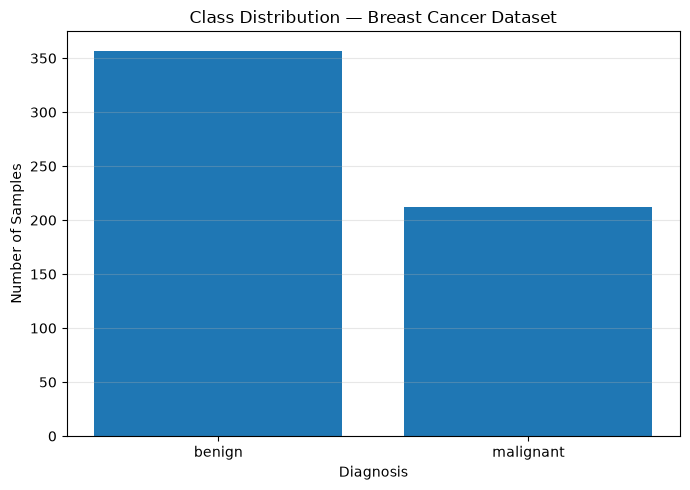

In [4]:
class_counts = df["Diagnosis"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(class_counts.index, class_counts.values)

plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.title("Class Distribution — Breast Cancer Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cancer_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Total samples: 569
Training samples: 455
Testing samples: 114

Training class distribution:
target
0    170
1    285
Name: count, dtype: int64

Testing class distribution:
target
0    42
1    72
Name: count, dtype: int64


In [6]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

print("Models prepared:")
for name in models:
    print("-", name)

Models prepared:
- Decision Tree
- Random Forest
- Gradient Boosting


In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validation strategy: 5-Fold Stratified Cross-Validation")
print("Models to compare:", len(models))
print("Scoring metrics: Accuracy and Macro F1")

Validation strategy: 5-Fold Stratified Cross-Validation
Models to compare: 3
Scoring metrics: Accuracy and Macro F1


In [8]:
benchmark_results = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        return_train_score=True
    )

    benchmark_results.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "CV Macro F1 Mean": scores["test_f1_macro"].mean(),
        "CV Macro F1 Std": scores["test_f1_macro"].std(),
        "Train Macro F1": scores["train_f1_macro"].mean()
    })

benchmark_df = pd.DataFrame(benchmark_results)

print("\nCross-validation benchmark completed!")
display(
    benchmark_df.sort_values(
        "CV Macro F1 Mean",
        ascending=False
    ).round(4)
)

Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating Gradient Boosting...

Cross-validation benchmark completed!


,Model,CV Accuracy Mean,CV Accuracy Std,CV Macro F1 Mean,CV Macro F1 Std,Train Macro F1
1,Random Forest,0.9626,0.0179,0.9602,0.0188,1.0
2,Gradient Boosting,0.9516,0.0149,0.9483,0.0158,1.0
0,Decision Tree,0.9165,0.0179,0.9119,0.0190,1.0


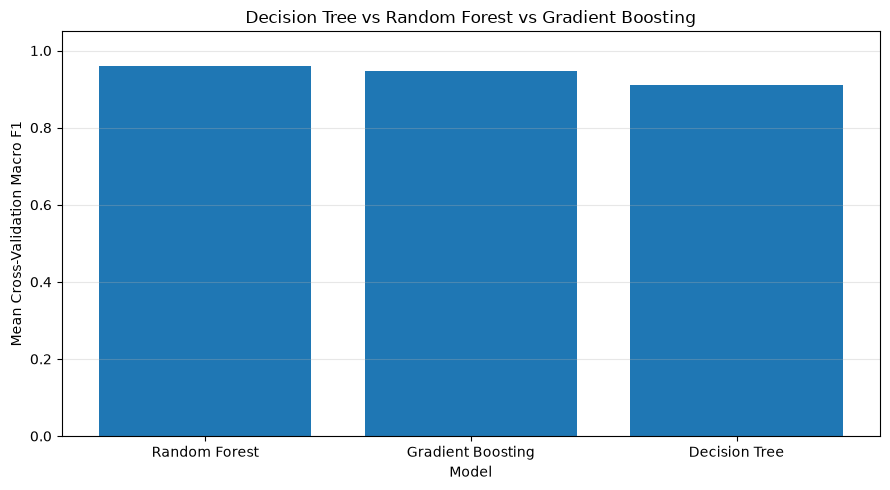

In [9]:
plot_df = benchmark_df.sort_values(
    "CV Macro F1 Mean",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_df["Model"],
    plot_df["CV Macro F1 Mean"]
)

plt.ylabel("Mean Cross-Validation Macro F1")
plt.xlabel("Model")
plt.title("Decision Tree vs Random Forest vs Gradient Boosting")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ensemble_cv_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
from sklearn.metrics import recall_score

test_results = []
fitted_models = {}
test_predictions = {}

for name, model in models.items():
    # Fit on the complete training set
    model.fit(X_train, y_train)

    # Predict on the held-out test set
    predictions = model.predict(X_test)

    fitted_models[name] = model
    test_predictions[name] = predictions

    test_results.append({
        "Model": name,
        "CV_Macro_F1": benchmark_df.loc[
            benchmark_df["Model"] == name,
            "CV Macro F1 Mean"
        ].iloc[0],
        "Test_Accuracy": accuracy_score(y_test, predictions),
        "Test_Macro_F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Malignant_Recall": recall_score(
            y_test, predictions, pos_label=0
        )
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df
    .sort_values("Test_Macro_F1", ascending=False)
    .round(4)
)

,Model,CV_Macro_F1,Test_Accuracy,Test_Macro_F1,Malignant_Recall
1,Random Forest,0.9602,0.9561,0.9526,0.9286
2,Gradient Boosting,0.9483,0.9561,0.9521,0.9048
0,Decision Tree,0.9119,0.9123,0.9075,0.9286


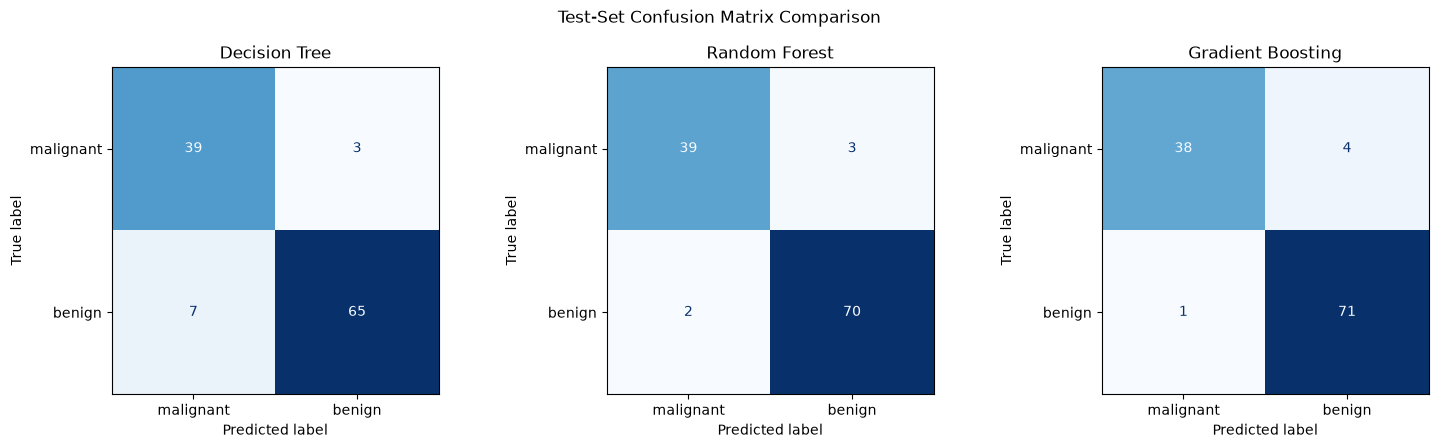

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (name, predictions) in zip(
    axes, test_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=cancer.target_names,
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.suptitle("Test-Set Confusion Matrix Comparison")
plt.tight_layout()

plt.savefig(
    "ensemble_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Feature,Importance
22,worst perimeter,0.1331
23,worst area,0.1281
27,worst concave points,0.1081
7,mean concave points,0.0944
20,worst radius,0.0906
0,mean radius,0.0587
2,mean perimeter,0.0552
3,mean area,0.0499
6,mean concavity,0.0462
26,worst concavity,0.0354


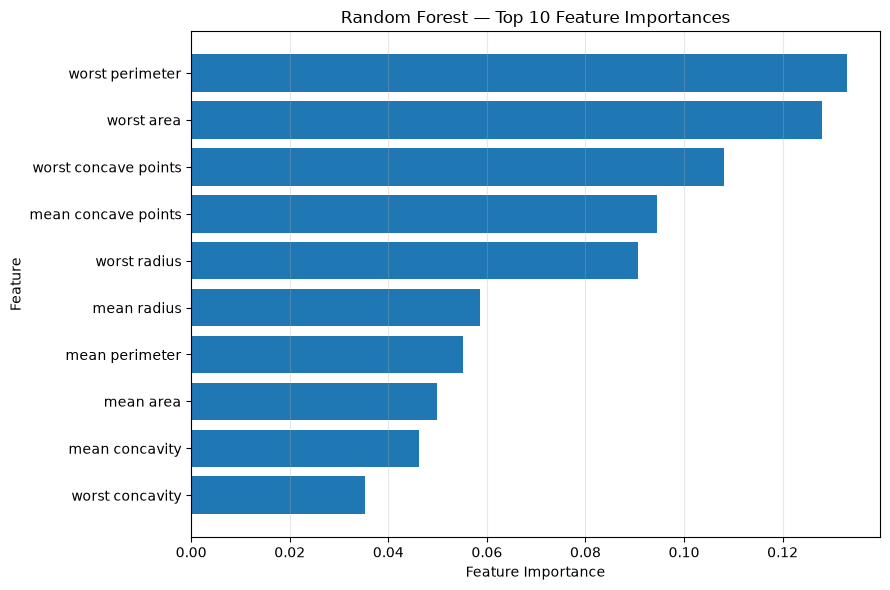

In [13]:
rf_model = fitted_models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(10).round(4))

top_features = importance_df.head(10).sort_values(
    "Importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 10 Feature Importances")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Compare cross-validation and test performance
summary = test_results_df.sort_values(
    "Test_Macro_F1",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("ENSEMBLE LEARNING BENCHMARK SUMMARY")
print("=" * 60)

display(summary.round(4))

print("\nBest model by held-out Test Macro F1:")
best_name = summary.loc[0, "Model"]
print(best_name)

print("\nTop 5 Random Forest features:")
display(importance_df.head(5).round(4))

print("\nSaved visualization files:")
print("- cancer_class_distribution.png")
print("- ensemble_cv_comparison.png")
print("- ensemble_confusion_matrices.png")
print("- random_forest_feature_importance.png")

ENSEMBLE LEARNING BENCHMARK SUMMARY


,Model,CV_Macro_F1,Test_Accuracy,Test_Macro_F1,Malignant_Recall
0,Random Forest,0.9602,0.9561,0.9526,0.9286
1,Gradient Boosting,0.9483,0.9561,0.9521,0.9048
2,Decision Tree,0.9119,0.9123,0.9075,0.9286



Best model by held-out Test Macro F1:
Random Forest

Top 5 Random Forest features:


,Feature,Importance
22,worst perimeter,0.1331
23,worst area,0.1281
27,worst concave points,0.1081
7,mean concave points,0.0944
20,worst radius,0.0906



Saved visualization files:
- cancer_class_distribution.png
- ensemble_cv_comparison.png
- ensemble_confusion_matrices.png
- random_forest_feature_importance.png
